In [1]:
 from pathlib import Path

for p in Path("/kaggle/input").rglob("*"):
       if p.is_dir() and p.name in {"classification_task", "segmentation_task"}:
           print(p)

/kaggle/input/datasets/briscdataset/brisc2025/brisc2025/segmentation_task
/kaggle/input/datasets/briscdataset/brisc2025/brisc2025/classification_task


In [2]:
from pathlib import Path 
root = Path("/kaggle/input/datasets/briscdataset/brisc2025/brisc2025")

seg_path = root / "segmentation_task"
class_path = root / "classification_task" / "train" 

print(sorted(p.name for p in class_path.iterdir() if p.is_dir()))

['glioma', 'meningioma', 'no_tumor', 'pituitary']


In [3]:
import torchvision.transforms as transforms
import torchvision.datasets as datasets




path = ("/kaggle/input/datasets/briscdataset/brisc2025/brisc2025/classification_task/train")

classification_data = datasets.ImageFolder(path)

print(len(classification_data))
print(classification_data.classes)

5000
['glioma', 'meningioma', 'no_tumor', 'pituitary']


In [4]:
from torchvision import datasets, transforms

transform = transforms.Compose([
       transforms.Grayscale(num_output_channels=1),
       transforms.Resize((128, 128)),
       transforms.ToTensor(),
   ])

classification_data_transform = datasets.ImageFolder(
       root="/kaggle/input/datasets/briscdataset/brisc2025/brisc2025/classification_task/train",
       transform=transform,
   )

img, label = classification_data_transform[0]

print(img.shape)       
print(img.min(), img.max())
print(label)

torch.Size([1, 128, 128])
tensor(0.) tensor(0.8863)
0


In [5]:
from torch.utils.data import random_split, DataLoader
import torch

generator = torch.Generator().manual_seed(42)
    
train_size = int(0.8 * len(classification_data_transform))
val_size = len(classification_data_transform) - train_size
    
train_data, val_data = random_split(
           classification_data_transform,
           [train_size, val_size],
           generator=generator,
       )
    
train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
val_loader = DataLoader(val_data, batch_size=64, shuffle=False)
    
images, labels = next(iter(train_loader))
    
print(images.shape)  
print(labels.shape) 
    
     
    


torch.Size([64, 1, 128, 128])
torch.Size([64])


In [6]:
labels_a = torch.cat([y for _, y in train_loader])
labels_b = torch.cat([y for _, y in train_loader])
print((labels_a == labels_b).all()) 

tensor(False)


In [7]:
import torch
from torch import nn


class ConvAutoencoder(nn.Module):
   def __init__(self, latent_dim=64):
       super().__init__()

       self.encoder = nn.Sequential(
           nn.Conv2d(1, 16, 4, stride=2, padding=1),
           nn.ReLU(),

           nn.Conv2d(16, 32, 4, stride=2, padding=1),
           nn.ReLU(),

           nn.Conv2d(32, 64, 4, stride=2, padding=1),
           nn.ReLU(),

           nn.Conv2d(64, 128, 4, stride=2, padding=1),
           nn.ReLU(),
       )

       self.to_latent = nn.Linear(128 * 8 * 8, latent_dim)
       self.from_latent = nn.Linear(latent_dim, 128 * 8 * 8)

       self.decoder = nn.Sequential(
           nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1),
           nn.ReLU(),

           nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1),
           nn.ReLU(),

           nn.ConvTranspose2d(32, 16, 4, stride=2, padding=1),
           nn.ReLU(),

           nn.ConvTranspose2d(16, 1, 4, stride=2, padding=1),
           nn.Sigmoid(),
       )

   def encode(self, x):
       x = self.encoder(x)
       x = x.flatten(start_dim=1)
       return self.to_latent(x)

   def forward(self, x):
       z = self.encode(x)
       x = self.from_latent(z)
       x = x.view(-1, 128, 8, 8)
       return self.decoder(x)


model = ConvAutoencoder(latent_dim=64)

images, _ = next(iter(train_loader))
reconstructed = model(images)

print(reconstructed.shape)

torch.Size([64, 1, 128, 128])


In [8]:
import torch
from torch import nn

device = "cuda" if torch.cuda.is_available() else "cpu"

def run_ae(latent_dim, epochs, tag):
   model = ConvAutoencoder(latent_dim).to(device)
   opt = torch.optim.Adam(model.parameters(), lr=1e-3)
   lossf = nn.MSELoss()
   hist, best = [], float("inf")

   for ep in range(epochs):
       model.train()
       tr = 0.0
       for x, _ in train_loader:                 
           x = x.to(device)
           loss = lossf(model(x), x)
           opt.zero_grad(); loss.backward(); opt.step()
           tr += loss.item() * x.size(0)
       tr /= len(train_loader.dataset)

       model.eval()
       va = 0.0
       with torch.no_grad():
           for x, _ in val_loader:
               x = x.to(device)
               va += lossf(model(x), x).item() * x.size(0)
       va /= len(val_loader.dataset)

       hist.append((tr, va))
       if va < best:
           best = va
           torch.save(model.state_dict(), f"best_{tag}.pt")
       print(f"ep {ep+1:02d}  train {tr:.5f}  val {va:.5f}")

   return model, hist, best

model, hist, best = run_ae(64, epochs=1, tag="smoke")


ep 01  train 0.03319  val 0.01834


In [9]:
m16, h16, b16 = run_ae(16, epochs=25, tag="d16")
m64, h64, b64 = run_ae(64, epochs=25, tag="d64")


ep 01  train 0.03513  val 0.01849
ep 02  train 0.01735  val 0.01571
ep 03  train 0.01384  val 0.01313
ep 04  train 0.01231  val 0.01222
ep 05  train 0.01152  val 0.01138
ep 06  train 0.01073  val 0.01074
ep 07  train 0.01013  val 0.01017
ep 08  train 0.00975  val 0.00989
ep 09  train 0.00928  val 0.00939
ep 10  train 0.00891  val 0.00926
ep 11  train 0.00851  val 0.00869
ep 12  train 0.00808  val 0.00856
ep 13  train 0.00792  val 0.00823
ep 14  train 0.00768  val 0.00818
ep 15  train 0.00752  val 0.00807
ep 16  train 0.00744  val 0.00801
ep 17  train 0.00719  val 0.00793
ep 18  train 0.00710  val 0.00771
ep 19  train 0.00700  val 0.00786
ep 20  train 0.00696  val 0.00762
ep 21  train 0.00681  val 0.00763
ep 22  train 0.00676  val 0.00752
ep 23  train 0.00668  val 0.00751
ep 24  train 0.00665  val 0.00756
ep 25  train 0.00663  val 0.00745
ep 01  train 0.04133  val 0.01894
ep 02  train 0.01593  val 0.01382
ep 03  train 0.01264  val 0.01232
ep 04  train 0.01145  val 0.01120
ep 05  train 0

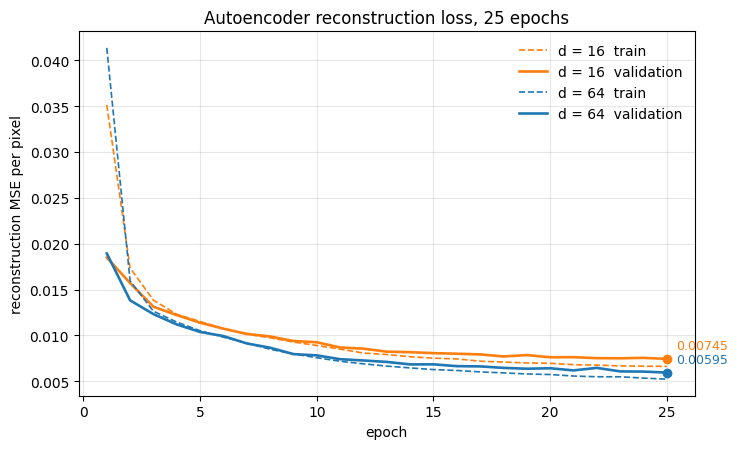

d16  best val 0.00745   final 0.00745
d64  best val 0.00595   final 0.00595


In [10]:
# --- ADDED: sheet page 3, "plot the curves" ---
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7.5, 4.6))

for hist_, name, colour in [(h16, "d = 16", "tab:orange"), (h64, "d = 64", "tab:blue")]:
    tr = [t for t, v in hist_]
    va = [v for t, v in hist_]
    ep = range(1, len(tr) + 1)
    ax.plot(ep, tr, color=colour, ls="--", lw=1.2, label=f"{name}  train")
    ax.plot(ep, va, color=colour, ls="-",  lw=1.9, label=f"{name}  validation")

    k = min(range(len(va)), key=lambda i: va[i])
    ax.plot(k + 1, va[k], "o", color=colour, ms=6, zorder=5)
    ax.annotate(f"{va[k]:.5f}", (k + 1, va[k]), textcoords="offset points",
                xytext=(7, 7), fontsize=9, color=colour)

ax.set_xlabel("epoch")
ax.set_ylabel("reconstruction MSE per pixel")
ax.set_title("Autoencoder reconstruction loss, 25 epochs")
ax.grid(alpha=0.3)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

print(f"d16  best val {min(v for _, v in h16):.5f}   final {h16[-1][1]:.5f}")
print(f"d64  best val {min(v for _, v in h64):.5f}   final {h64[-1][1]:.5f}")

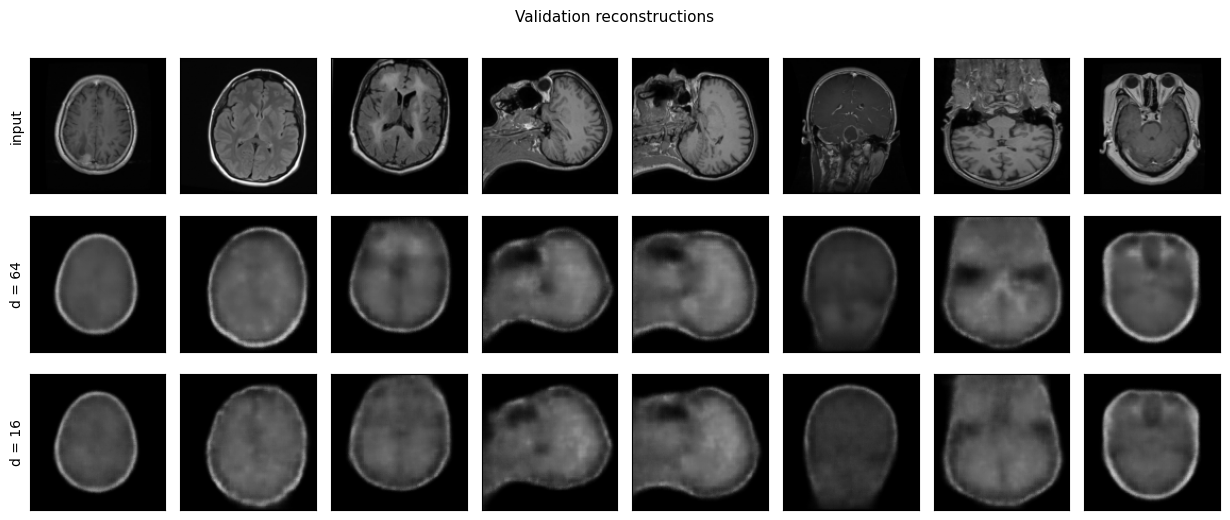

MSE on these 8 images   d64 0.00608   d16 0.00735


In [11]:
# --- ADDED: sheet page 3, "display several input/reconstruction pairs" ---
import torch
import matplotlib.pyplot as plt

N = 8
x, _ = next(iter(val_loader))
x = x[:N].to(device)

m64.eval()
m16.eval()
with torch.no_grad():
    r64 = m64(x).cpu()
    r16 = m16(x).cpu()
x = x.cpu()

rows = [(x, "input"), (r64, "d = 64"), (r16, "d = 16")]

fig, axes = plt.subplots(len(rows), N, figsize=(1.55 * N, 1.8 * len(rows)))
for r, (batch, label) in enumerate(rows):
    for c in range(N):
        ax = axes[r, c]
        # vmin/vmax fixed: otherwise each panel autoscales and a washed-out
        # reconstruction looks sharper than it is
        ax.imshow(batch[c, 0], cmap="gray", vmin=0, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
        if c == 0:
            ax.set_ylabel(label, fontsize=10)
fig.suptitle("Validation reconstructions", fontsize=11)
plt.tight_layout()
plt.show()

print(f"MSE on these {N} images   d64 {((r64 - x) ** 2).mean():.5f}"
      f"   d16 {((r16 - x) ** 2).mean():.5f}")

In [12]:
# --- ADDED: `model` was still the 1-epoch smoke run from the run_ae cell.
# Cell 8 bound m16 and m64 and never rebound `model`, so every downstream
# number (KNN, silhouette, projections, interpolation) came from a model
# trained for one epoch at val 0.01912 instead of the d64 model at 0.00610.
model = m64
model.eval()

assert model is m64, "still pointing at the smoke model"
print(f"encoder rebound to m64  |  latent dim {model.to_latent.out_features}"
      f"  |  best val MSE {b64:.5f}")

encoder rebound to m64  |  latent dim 64  |  best val MSE 0.00595


In [13]:
encode_loader = DataLoader(train_data, batch_size=64, shuffle=False)  
import torch
from tqdm import tqdm

model.eval()

def encode_split(loader):
    Z, Y = [], []
    with torch.no_grad():
        for x, y in tqdm(loader):
            z = model.encode(x.to(device))
            Z.append(z.cpu())
            Y.append(y)
    return torch.cat(Z).numpy(), torch.cat(Y).numpy()

Z_train, y_train = encode_split(encode_loader)   
Z_val,   y_val   = encode_split(val_loader)

print(Z_train.shape, y_train.shape)   
print(Z_val.shape,   y_val.shape)     

100%|██████████| 16/16 [00:02<00:00,  5.40it/s]

(4000, 64) (4000,)
(1000, 64) (1000,)


In [14]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score




knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(Z_train, y_train)
y_pred = knn.predict(Z_val)

print("\n Classification Evaluation ")
print(f"Accuracy Score: {accuracy_score(y_val, y_pred):.4f}")
print(classification_report(y_val, y_pred))



 Classification Evaluation 
Accuracy Score: 0.8750
              precision    recall  f1-score   support

           0       0.80      0.87      0.83       206
           1       0.83      0.80      0.81       267
           2       0.94      0.85      0.89       239
           3       0.93      0.97      0.95       288

    accuracy                           0.88      1000
   macro avg       0.87      0.87      0.87      1000
weighted avg       0.88      0.88      0.87      1000



In [15]:
from sklearn.metrics import silhouette_score
print(silhouette_score(Z_val, y_val))

0.012823101


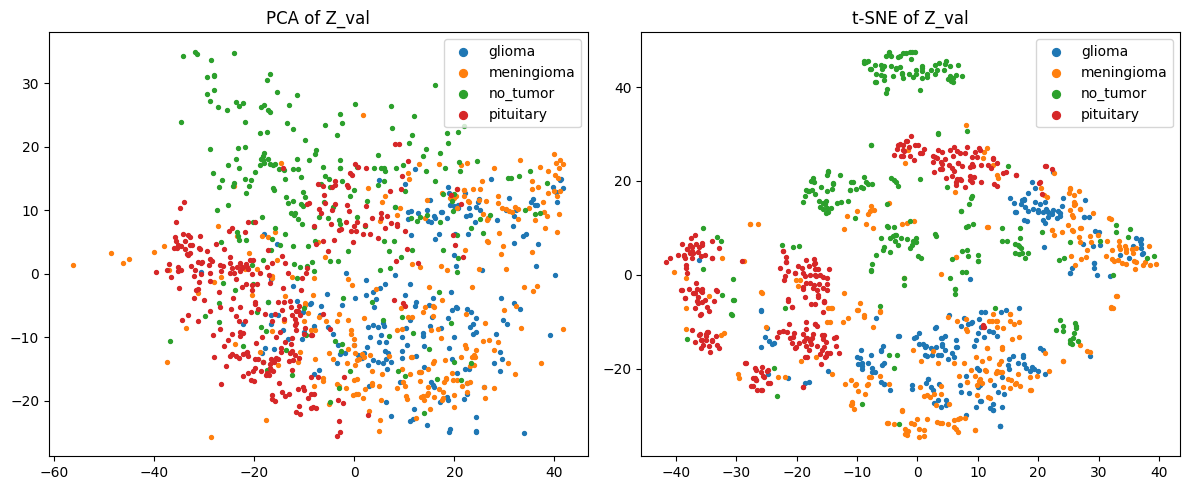

In [16]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

P = PCA(n_components=2).fit_transform(Z_val)
T = TSNE(n_components=2, random_state=42).fit_transform(Z_val)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, XY, name in zip(axes, [P, T], ['PCA', 't-SNE']):
    for k, cname in enumerate(classification_data_transform.classes):
        m = y_val == k
        ax.scatter(XY[m, 0], XY[m, 1], s=8, label=cname)
    ax.set_title(f'{name} of Z_val')
    ax.legend(markerscale=2)
plt.tight_layout()
plt.show()


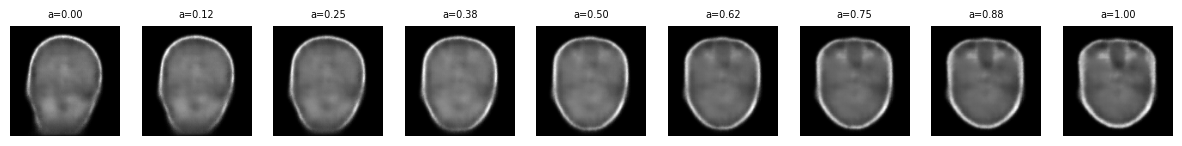

In [17]:

import torch
import numpy as np
import matplotlib.pyplot as plt

def decode(z):
    return model.decoder(model.from_latent(z).view(-1, 128, 8, 8))


ia = int(np.where(y_val == 0)[0][0])    
ib = int(np.where(y_val == 3)[0][0])     
xa = val_data[ia][0]
xb = val_data[ib][0]

model.eval()
with torch.no_grad():
    z0 = model.encode(xa[None].to(device))
    z1 = model.encode(xb[None].to(device))
    frames = []
    for i in range(9):                     
        t = i / 8.0
        zt = (1 - t) * z0 + t * z1          
        frames.append(decode(zt).cpu())

fig, axes = plt.subplots(1, 9, figsize=(15, 2))
for i, ax in enumerate(axes):
    ax.imshow(frames[i][0, 0], cmap='gray')
    ax.set_title(f'a={i/8:.2f}', fontsize=7)
    ax.axis('off')
plt.show()


In [18]:
# --- ADDED: copy these into the markdown answers below ---
from sklearn.metrics import accuracy_score, silhouette_score

print("--- numbers for the write-up ---")
print(f"KNN 5-NN accuracy : {accuracy_score(y_val, y_pred):.4f}")
print(f"silhouette        : {silhouette_score(Z_val, y_val):.4f}")
print(f"d16 best val MSE  : {min(v for _, v in h16):.5f}")
print(f"d64 best val MSE  : {min(v for _, v in h64):.5f}")
print(f"chance accuracy   : {1 / len(classification_data_transform.classes):.4f}")

--- numbers for the write-up ---
KNN 5-NN accuracy : 0.8750
silhouette        : 0.0128
d16 best val MSE  : 0.00745
d64 best val MSE  : 0.00595
chance accuracy   : 0.2500


## Exercise 2 answers

**Q1 — Why do codes cluster without labels?**  
Class signal is in the pixels. A small bottleneck keeps large factors (mass location, size, texture) that also define tumour type, so 5-NN on codes beats chance. Silhouette can stay low if clusters are ribbons, not blobs.

**Q2 — Latent size d.**  
d16 vs d64 (25 epochs): val MSE 0.00745 vs 0.00610. Larger d reconstructs better; very small d collapses detail and weakens class structure in the codes.

**Q3 — Labels in the loss?**  
No. Training is unsupervised MSE. Labels are only for colouring plots and scoring 5-NN / silhouette.
